# Step 5. EDA & Visualization — Origin Airport Analysis

## Objective

This notebook compares arrival delay patterns across three major New York City area departure airports: EWR, JFK, and LGA.

We examine flight counts, mean and median arrival delays, moderate and severe delay rates, and the distribution of arrival delays.

This analysis uses the cleaned flight dataset from Step 3. The findings are descriptive and do not establish that the departure airport itself causes arrival delays.

## 1. Load & Validate Data

Load the cleaned flight dataset and check the origin airport and arrival delay variables.

Verify that all flights belong to one of the three airports and that arrival delay values are available.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

data_path = Path("data/cleaned/analysis_ready_flights.csv")
fig_dir = Path("results/figures")
table_dir = Path("results/tables")

fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

analysis = pd.read_csv(data_path)

airport_order = ["EWR", "JFK", "LGA"]

print("Dataset shape:", analysis.shape)
print("Missing origin:", analysis["origin"].isna().sum())
print("Missing arrival delay:", analysis["arr_delay"].isna().sum())

assert analysis["arr_delay"].notna().all()
assert analysis["origin"].isin(airport_order).all()

airport_data = analysis.copy()

print("Total flights:", f"{len(airport_data):,}")

display(airport_data[["origin", "arr_delay"]].head())

Dataset shape: (327346, 34)
Missing origin: 0
Missing arrival delay: 0
Total flights: 327,346


,origin,arr_delay
0,EWR,11.0
1,LGA,20.0
2,JFK,33.0
3,JFK,-18.0
4,LGA,-25.0


## 2. Flight Distribution by Origin Airport

Compare the number and percentage of flights departing from EWR, JFK, and LGA.

Differences in sample sizes should be considered when interpreting airport-level delay statistics.

In [2]:
airport_counts = (
    airport_data["origin"]
    .value_counts()
    .reindex(airport_order)
)

airport_shares = pd.DataFrame({
    "Flights": airport_counts,
    "Share_of_Total_Pct": airport_counts / len(airport_data) * 100
})

display(airport_shares.round(2))

,Flights,Share_of_Total_Pct
origin,,
EWR,117127,35.78
JFK,109079,33.32
LGA,101140,30.90


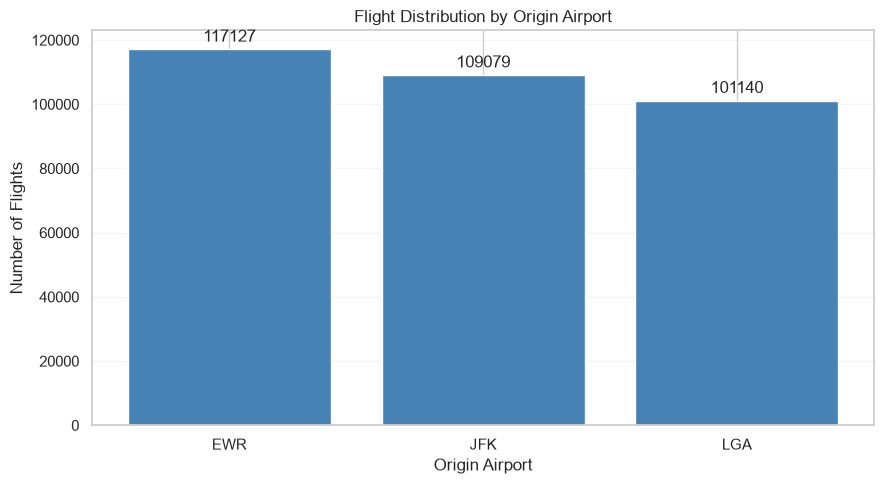

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    airport_counts.index,
    airport_counts.values,
    color="steelblue"
)

ax.bar_label(bars, fmt="%.0f", padding=3)

ax.set(
    title="Flight Distribution by Origin Airport",
    xlabel="Origin Airport",
    ylabel="Number of Flights"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "airport_flight_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Arrival Delay Statistics by Origin Airport

Compare the mean, median, standard deviation, minimum, and maximum arrival delays across airports.

We also calculate the percentages of flights delayed more than 15, 60, and 120 minutes.

In [4]:
airport_stats = (
    airport_data.groupby("origin")["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(airport_order)
)

display(airport_stats.round(2))

assert airport_stats["Flights"].sum() == len(airport_data)

print("Airport statistics calculated successfully!")

,Flights,Mean,Median,Std,Min,Max,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
origin,,,,,,,,,
EWR,117127,9.11,-4.0,45.53,-86.0,1109.0,25.59,9.49,3.39
JFK,109079,5.55,-6.0,44.28,-79.0,1272.0,22.97,8.19,2.90
LGA,101140,5.78,-5.0,43.86,-68.0,915.0,22.36,7.64,2.87


Airport statistics calculated successfully!


### Mean vs. Median Arrival Delay by Airport

Compare mean and median arrival delays to understand differences in typical delay patterns and the possible influence of extreme delays.

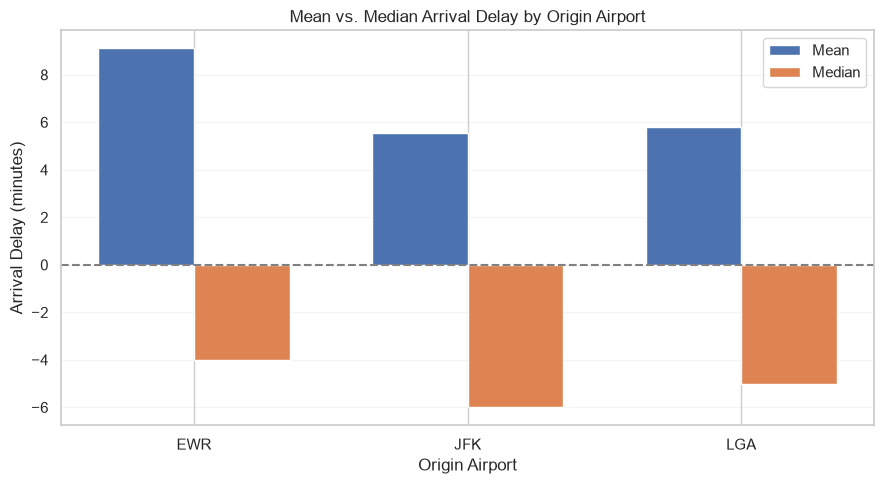

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(airport_order))
width = 0.35

ax.bar(
    x - width / 2,
    airport_stats["Mean"],
    width,
    label="Mean"
)

ax.bar(
    x + width / 2,
    airport_stats["Median"],
    width,
    label="Median"
)

ax.set_xticks(x)
ax.set_xticklabels(airport_order)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Mean vs. Median Arrival Delay by Origin Airport",
    xlabel="Origin Airport",
    ylabel="Arrival Delay (minutes)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "airport_mean_vs_median.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Delay Rates by Origin Airport

Compare the percentages of flights delayed more than 15, 60, and 120 minutes across the three airports.

These measures provide additional information about the frequency of moderate and severe delays beyond the average arrival delay.

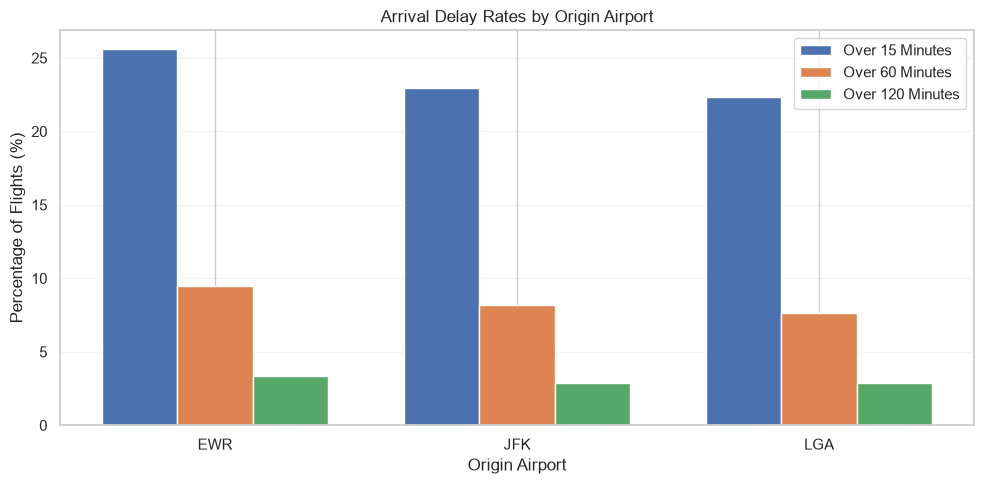

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(airport_order))
width = 0.25

ax.bar(
    x - width,
    airport_stats["Delay_Over_15_Pct"],
    width,
    label="Over 15 Minutes"
)

ax.bar(
    x,
    airport_stats["Delay_Over_60_Pct"],
    width,
    label="Over 60 Minutes"
)

ax.bar(
    x + width,
    airport_stats["Delay_Over_120_Pct"],
    width,
    label="Over 120 Minutes"
)

ax.set_xticks(x)
ax.set_xticklabels(airport_order)

ax.set(
    title="Arrival Delay Rates by Origin Airport",
    xlabel="Origin Airport",
    ylabel="Percentage of Flights (%)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "airport_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Arrival Delay Distribution by Airport

Compare the distribution of arrival delays using boxplots.

The full dataset is used to calculate boxplot statistics. The vertical axis is limited to −60 to 180 minutes for readability, and individual outlier points are hidden.

Extreme delays remain included in the descriptive statistics.

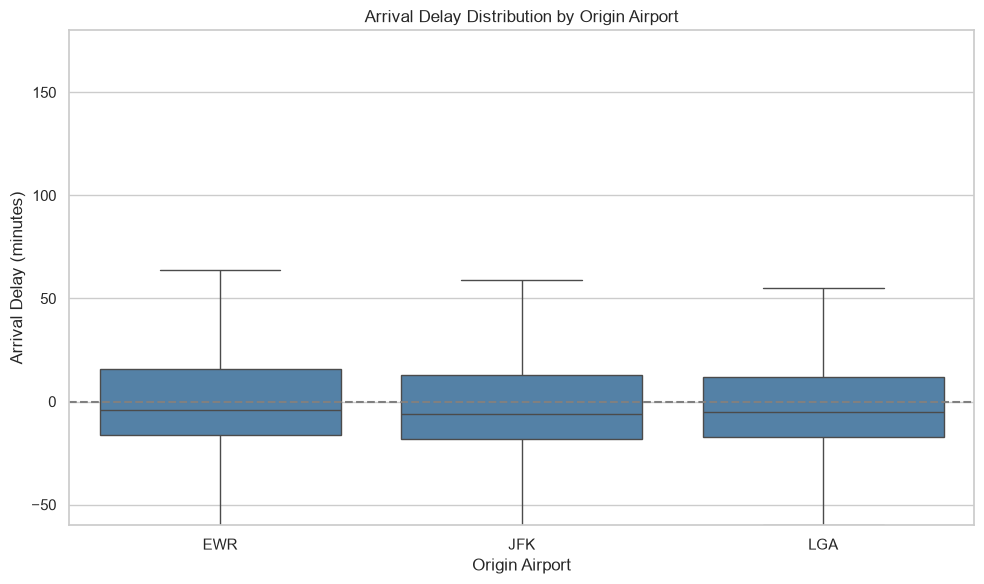

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=airport_data,
    x="origin",
    y="arr_delay",
    order=airport_order,
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.set_ylim(-60, 180)
ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delay Distribution by Origin Airport",
    xlabel="Origin Airport",
    ylabel="Arrival Delay (minutes)"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "airport_delay_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Extreme Delays by Airport

Examine the number and percentage of flights delayed more than 120 minutes.

We also compare the maximum recorded arrival delay at each airport.

The percentage of extreme delays is used alongside the number of flights to account for differences in airport sample sizes.

In [8]:
extreme_stats = (
    airport_data.groupby("origin")["arr_delay"]
    .agg(
        Flights="count",
        Delays_Over_120=lambda x: (x > 120).sum(),
        Extreme_Delay_Pct=lambda x: (x > 120).mean() * 100,
        Maximum_Delay="max"
    )
    .reindex(airport_order)
)

extreme_stats["Share_of_Total_Pct"] = (
    extreme_stats["Flights"] / len(airport_data) * 100
)

display(extreme_stats.round(2))

,Flights,Delays_Over_120,Extreme_Delay_Pct,Maximum_Delay,Share_of_Total_Pct
origin,,,,,
EWR,117127,3965,3.39,1109.0,35.78
JFK,109079,3166,2.90,1272.0,33.32
LGA,101140,2903,2.87,915.0,30.90


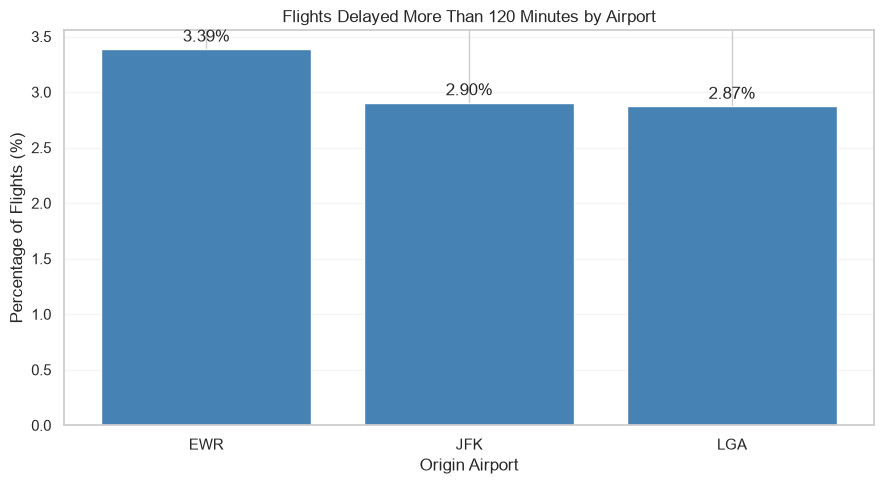

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    extreme_stats.index,
    extreme_stats["Extreme_Delay_Pct"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set(
    title="Flights Delayed More Than 120 Minutes by Airport",
    xlabel="Origin Airport",
    ylabel="Percentage of Flights (%)"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "airport_extreme_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Arrival Delays by Airport and Season

Compare mean arrival delays across airports and seasons.

This exploratory comparison helps determine whether airport-level delay patterns are similar throughout the year or vary by season.

The analysis does not control for differences in airlines, routes, departure times, or weather conditions.

In [10]:
season_order = ["Winter", "Spring", "Summer", "Fall"]

airport_season_stats = (
    airport_data.groupby(["origin", "season"])["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100
    )
    .round(2)
)

display(airport_season_stats)

Flights   Mean  Median  Delay_Over_15_Pct
origin season                                           
EWR    Fall      28971  -0.41    -8.0              16.11
       Spring    30549  10.03    -3.0              27.14
       Summer    30006  12.96    -3.0              28.44
       Winter    27601  13.89     1.0              30.72
JFK    Fall      26529  -2.99    -9.0              14.20
       Spring    27780   3.87    -7.0              22.25
       Summer    28809  14.47    -2.0              30.50
       Winter    25961   6.19    -4.0              24.32
LGA    Fall      27099  -0.36    -8.0              17.04
       Spring    25265   6.15    -6.0              22.87
       Summer    25309  11.34    -4.0              26.77
       Winter    23467   6.49    -3.0              23.18

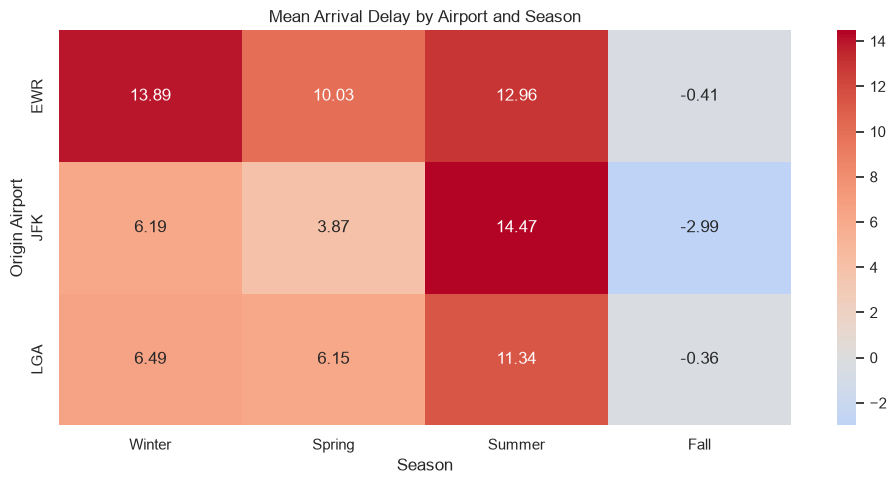

In [11]:
airport_season_pivot = (
    airport_season_stats["Mean"]
    .unstack("season")
    .reindex(index=airport_order, columns=season_order)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    airport_season_pivot,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set(
    title="Mean Arrival Delay by Airport and Season",
    xlabel="Season",
    ylabel="Origin Airport"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "airport_season_delay_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Save Results

Export airport-level descriptive statistics, extreme delay statistics, and seasonal comparisons for use in the final project report.

In [12]:
airport_shares.round(2).to_csv(
    table_dir / "airport_flight_counts.csv",
    index_label="origin"
)

airport_stats.round(2).to_csv(
    table_dir / "airport_statistics.csv",
    index_label="origin"
)

extreme_stats.round(2).to_csv(
    table_dir / "airport_extreme_delays.csv",
    index_label="origin"
)

airport_season_stats.to_csv(
    table_dir / "airport_season_statistics.csv"
)

print("All airport analysis tables saved successfully!")

All airport analysis tables saved successfully!


In [13]:
print("=== ORIGIN AIRPORT EDA SUMMARY ===")

print(
    f"\nOverall mean arrival delay: "
    f"{airport_data['arr_delay'].mean():.2f} minutes"
)

print(
    f"Overall median arrival delay: "
    f"{airport_data['arr_delay'].median():.2f} minutes"
)

highest_mean = airport_stats["Mean"].idxmax()
lowest_mean = airport_stats["Mean"].idxmin()

highest_15 = airport_stats["Delay_Over_15_Pct"].idxmax()
lowest_15 = airport_stats["Delay_Over_15_Pct"].idxmin()

highest_60 = airport_stats["Delay_Over_60_Pct"].idxmax()
highest_120 = airport_stats["Delay_Over_120_Pct"].idxmax()

print(
    f"\nHighest mean delay: {highest_mean} "
    f"({airport_stats.loc[highest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"Lowest mean delay: {lowest_mean} "
    f"({airport_stats.loc[lowest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"\nHighest >15 min delay rate: {highest_15} "
    f"({airport_stats.loc[highest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Lowest >15 min delay rate: {lowest_15} "
    f"({airport_stats.loc[lowest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Highest >60 min delay rate: {highest_60} "
    f"({airport_stats.loc[highest_60, 'Delay_Over_60_Pct']:.2f}%)"
)

print(
    f"Highest >120 min delay rate: {highest_120} "
    f"({airport_stats.loc[highest_120, 'Delay_Over_120_Pct']:.2f}%)"
)

print("\nAirport Statistics:")
display(airport_stats.round(2))

print("\nAirport by Season:")
display(airport_season_pivot.round(2))

=== ORIGIN AIRPORT EDA SUMMARY ===

Overall mean arrival delay: 6.90 minutes
Overall median arrival delay: -5.00 minutes

Highest mean delay: EWR (9.11 minutes)
Lowest mean delay: JFK (5.55 minutes)

Highest >15 min delay rate: EWR (25.59%)
Lowest >15 min delay rate: LGA (22.36%)
Highest >60 min delay rate: EWR (9.49%)
Highest >120 min delay rate: EWR (3.39%)

Airport Statistics:


,Flights,Mean,Median,Std,Min,Max,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
origin,,,,,,,,,
EWR,117127,9.11,-4.0,45.53,-86.0,1109.0,25.59,9.49,3.39
JFK,109079,5.55,-6.0,44.28,-79.0,1272.0,22.97,8.19,2.90
LGA,101140,5.78,-5.0,43.86,-68.0,915.0,22.36,7.64,2.87



Airport by Season:


season,Winter,Spring,Summer,Fall
origin,,,,
EWR,13.89,10.03,12.96,-0.41
JFK,6.19,3.87,14.47,-2.99
LGA,6.49,6.15,11.34,-0.36


## 9. Key Findings and Limitations

### Key Findings

The overall mean arrival delay was 6.90 minutes, while the median was −5 minutes, suggesting that some large delays increased the average.

EWR had the highest mean arrival delay (9.11 minutes), followed by LGA (5.78 minutes) and JFK (5.55 minutes).

EWR also had the highest percentage of flights delayed more than 15 minutes (25.59%), 60 minutes (9.49%), and 120 minutes (3.39%). LGA had the lowest percentage of flights delayed more than 15 minutes (22.36%).

The seasonal comparison showed that arrival delay patterns differed across airports. EWR had its highest mean delay in Winter (13.89 minutes), while JFK and LGA had their highest mean delays in Summer (14.47 and 11.34 minutes, respectively).

Fall had the lowest mean arrival delays at all three airports: EWR (−0.41 minutes), JFK (−2.99 minutes), and LGA (−0.36 minutes).

Overall, EWR showed greater average arrival delays and higher severe delay rates than the other two airports. However, the seasonal results suggest that airport-level delay patterns may vary throughout the year.

### Limitations

This analysis only includes flights departing from New York City airports in 2013, so the findings may not represent current flight operations.

The number of flights differed across airports: EWR had 117,127 flights, JFK had 109,079, and LGA had 101,140.

Differences in airlines, destinations, scheduled departure times, flight distances, and weather conditions may also contribute to the observed delay patterns. These factors were not controlled for in this exploratory analysis.

Extreme delays may influence mean arrival delays. In addition, the descriptive comparisons do not establish that the departure airport itself causes flight delays.

### Data Preparation and Quality Notes

This analysis uses the cleaned flight dataset prepared in Step 3, containing 327,346 flights.

Flights with missing arrival delay values were excluded during data cleaning.

The `origin` variable identifies the departure airport, and all flights in the cleaned dataset belong to EWR, JFK, or LGA.

Airport-level statistics were calculated using the same cleaned dataset. The analysis also used the `season` variable created during Step 3 to compare arrival delays across airports and seasons.

Mean and median arrival delays, standard deviations, and delay rates above 15, 60, and 120 minutes were calculated for each airport.